<a href="https://colab.research.google.com/github/itsafnan0904-dot/Machine-learning/blob/ML-branch/Pharmacy_Sales_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pharmacy Store Daily Sales Prediction
**Students:** Afnan Jawad and Muhammad Ali  
**Dataset:** https://www.kaggle.com/competitions/rossmann-store-sales/data  
**GitHub:** https://github.com/itsafnan0904-dot/Machine-learning  
Ali is the colaborator in github

The data is the same Rossmann data as on Kaggle. This notebook loads it directly from a public GitHub copy, so no download or upload is needed (it works in Google Colab). To use your own files instead, change the two lines in the "Load" cell to `pd.read_csv("train.csv")` and `pd.read_csv("store.csv")`.

## 1. Problem definition
- **Goal:** predict the daily **Sales** of a store.
- **Type:** regression (the target is a number).
- **Success:** the models should do better than simply guessing the average sales. We compare models using MAE, RMSE and R².

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Loading and data preprocessing


In [4]:
base = "https://raw.githubusercontent.com/RPI-DATA/tutorials-intro/master/rossmann-store-sales/rossmann-store-sales/"
train = pd.read_csv(base + "train.csv", low_memory=False)
store = pd.read_csv(base + "store.csv")
print(train.shape, store.shape)
train.head()

(1017209, 9) (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [6]:
train.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [24]:
store.describe()

,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00000,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000
mean,558.00000,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573
std,322.01708,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935
min,1.00000,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000
25%,279.50000,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000
50%,558.00000,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000
75%,836.50000,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000
max,1115.00000,75860.000000,12.000000,2015.000000,1.000000,50.000000,2015.000000


In [23]:
print(train.duplicated().sum())
df = df.drop_duplicates()

0


## 3. Data cleaning

In [7]:
# check missing values and duplicates
print("Missing values in train:")
print(train.isnull().sum())
print("\nMissing values in store:")
print(store.isnull().sum())
print("\nDuplicate rows:", train.duplicated().sum())

Missing values in train:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Missing values in store:
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

Duplicate rows: 0


In [25]:
# join the two files using the Store column
df = train.merge(store, on="Store")

print(df)

         Store  DayOfWeek        Date  Sales  Customers  Open  Promo  \
0            1          5  2015-07-31   5263        555     1      1   
1            2          5  2015-07-31   6064        625     1      1   
2            3          5  2015-07-31   8314        821     1      1   
3            4          5  2015-07-31  13995       1498     1      1   
4            5          5  2015-07-31   4822        559     1      1   
...        ...        ...         ...    ...        ...   ...    ...   
1017204   1111          2  2013-01-01      0          0     0      0   
1017205   1112          2  2013-01-01      0          0     0      0   
1017206   1113          2  2013-01-01      0          0     0      0   
1017207   1114          2  2013-01-01      0          0     0      0   
1017208   1115          2  2013-01-01      0          0     0      0   

        StateHoliday  SchoolHoliday StoreType Assortment  CompetitionDistance  \
0                  0              1         c         

In [27]:
# fix the date type
df["Date"] = pd.to_datetime(df["Date"])
print(df["Date"].head())
print(df["Date"].dtype)

0   2015-07-31
1   2015-07-31
2   2015-07-31
3   2015-07-31
4   2015-07-31
Name: Date, dtype: datetime64[ns]
datetime64[ns]


In [30]:
# remove duplicates
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)

0
(1017209, 18)


In [ ]:
# keep only days when the store was open and had sales
df = df[(df["Open"] == 1) & (df["Sales"] > 0)]


In [32]:
# fill missing competition distance with the median
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(df["CompetitionDistance"].median())
print(df["CompetitionDistance"].isna().sum())   # should print 0

0


In [36]:
# turn text columns into numbers
df["StateHoliday"] = df["StateHoliday"].astype(str).map({"0": 0, "a": 1, "b": 2, "c": 3}).fillna(0)
df["StoreType"] = df["StoreType"].map({"a": 1, "b": 2, "c": 3, "d": 4})
df["Assortment"] = df["Assortment"].map({"a": 1, "b": 2, "c": 3})
print(df)



         Store  DayOfWeek       Date  Sales  Customers  Open  Promo  \
0            1          5 2015-07-31   5263        555     1      1   
1            2          5 2015-07-31   6064        625     1      1   
2            3          5 2015-07-31   8314        821     1      1   
3            4          5 2015-07-31  13995       1498     1      1   
4            5          5 2015-07-31   4822        559     1      1   
...        ...        ...        ...    ...        ...   ...    ...   
1017204   1111          2 2013-01-01      0          0     0      0   
1017205   1112          2 2013-01-01      0          0     0      0   
1017206   1113          2 2013-01-01      0          0     0      0   
1017207   1114          2 2013-01-01      0          0     0      0   
1017208   1115          2 2013-01-01      0          0     0      0   

         StateHoliday  SchoolHoliday  StoreType  Assortment  \
0                 0.0              1        NaN         NaN   
1                 0.0

In [38]:
# new columns from the date
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
print(df)

         Store  DayOfWeek       Date  Sales  Customers  Open  Promo  \
0            1          5 2015-07-31   5263        555     1      1   
1            2          5 2015-07-31   6064        625     1      1   
2            3          5 2015-07-31   8314        821     1      1   
3            4          5 2015-07-31  13995       1498     1      1   
4            5          5 2015-07-31   4822        559     1      1   
...        ...        ...        ...    ...        ...   ...    ...   
1017204   1111          2 2013-01-01      0          0     0      0   
1017205   1112          2 2013-01-01      0          0     0      0   
1017206   1113          2 2013-01-01      0          0     0      0   
1017207   1114          2 2013-01-01      0          0     0      0   
1017208   1115          2 2013-01-01      0          0     0      0   

         StateHoliday  SchoolHoliday  StoreType  ...  CompetitionDistance  \
0                 0.0              1        NaN  ...               127

**What we did:** joined both files, removed closed days and zero-sales days, filled missing competition distance with the median, converted letters to numbers, and made Year / Month / Day columns. We did not use `Customers` because we would not know it before the day.

## 4. Exploratory data analysis (EDA)

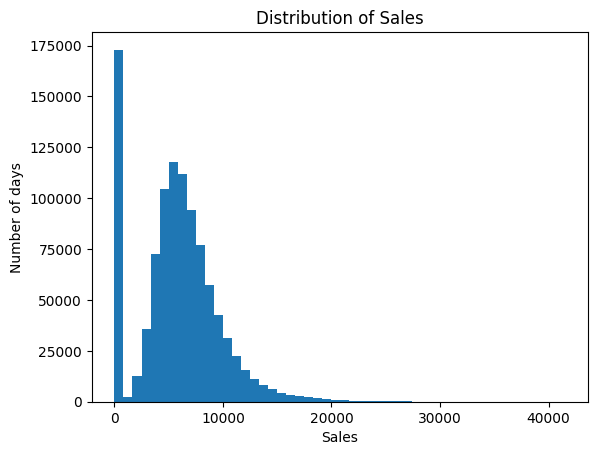

In [39]:
plt.hist(df["Sales"], bins=50)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of days")
plt.show()

*Most days have sales between about 4,000 and 9,000, with a few very high days.*

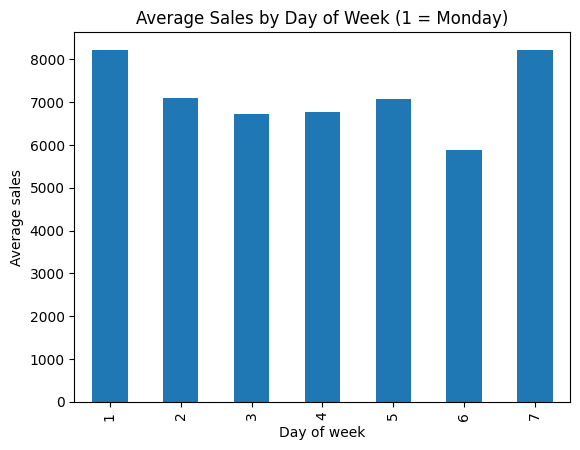

In [10]:
df.groupby("DayOfWeek")["Sales"].mean().plot(kind="bar")
plt.title("Average Sales by Day of Week (1 = Monday)")
plt.xlabel("Day of week")
plt.ylabel("Average sales")
plt.show()

*Shows which weekdays are busiest.*

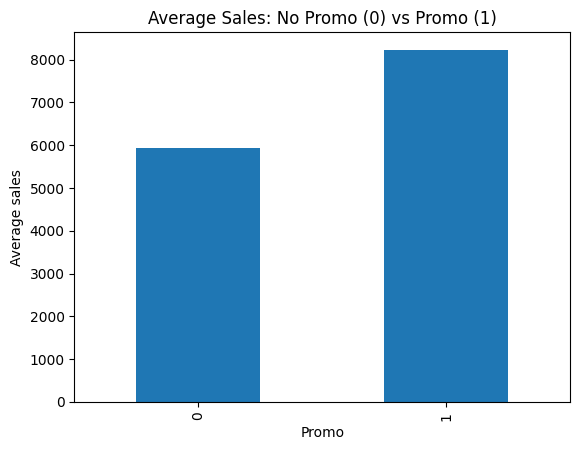

In [11]:
df.groupby("Promo")["Sales"].mean().plot(kind="bar")
plt.title("Average Sales: No Promo (0) vs Promo (1)")
plt.xlabel("Promo")
plt.ylabel("Average sales")
plt.show()

*Days with a promotion have higher average sales.*

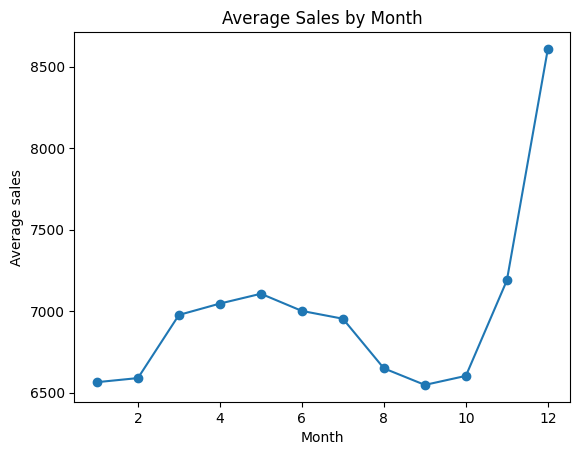

In [12]:
df.groupby("Month")["Sales"].mean().plot(kind="line", marker="o")
plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average sales")
plt.show()

*Shows the yearly pattern, for example the December rise.*

In [13]:
df[["Sales", "Promo", "DayOfWeek", "SchoolHoliday", "CompetitionDistance", "Month"]].corr()

,Sales,Promo,DayOfWeek,SchoolHoliday,CompetitionDistance,Month
Sales,1.000000,0.368199,-0.178753,0.038635,-0.035907,0.073589
Promo,0.368199,1.000000,-0.289268,0.028971,-0.002392,-0.006412
DayOfWeek,-0.178753,-0.289268,1.000000,-0.139319,0.005540,-0.019710
SchoolHoliday,0.038635,0.028971,-0.139319,1.000000,-0.004256,0.118467
CompetitionDistance,-0.035907,-0.002392,0.005540,-0.004256,1.000000,0.003882
Month,0.073589,-0.006412,-0.019710,0.118467,0.003882,1.000000


*The correlation table shows which columns are related to sales. Promo is the strongest of these.*

## 5. Choose features and split the data
We train on the older data and test on the **last 6 weeks**, like predicting the future. We also add `StoreAvg` (the average sales of each store, calculated from the training data only), because some stores are much bigger than others.

In [14]:
train_df = df[df["Date"] < "2015-06-19"].copy()
test_df = df[df["Date"] >= "2015-06-19"].copy()

# average sales of each store, calculated from the training data only
store_avg = train_df.groupby("Store")["Sales"].mean()
train_df["StoreAvg"] = train_df["Store"].map(store_avg)
test_df["StoreAvg"] = test_df["Store"].map(store_avg)

features = ["Store", "StoreAvg", "DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday",
            "StoreType", "Assortment", "CompetitionDistance", "Year", "Month", "Day"]

X_train, y_train = train_df[features], train_df["Sales"]
X_test, y_test = test_df[features], test_df["Sales"]
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 802942 | Testing rows: 41396


## 6. Build and compare models

In [40]:
results = []

def evaluate(name, predictions):
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    results.append([name, mae, rmse, r2])

# Baseline: always predict the average sales
baseline = np.full(len(y_test), y_train.mean())
evaluate("Baseline (average)", baseline)

# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate("Linear Regression", lr.predict(X_test))

# Model 2: Decision Tree
dt = DecisionTreeRegressor(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
evaluate("Decision Tree", dt.predict(X_test))

# Model 3: Random Forest (a smaller sample of rows is used so it runs faster)
small = train_df.sample(200000, random_state=42) if len(train_df) > 200000 else train_df
rf = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(small[features], small["Sales"])
evaluate("Random Forest", rf.predict(X_test))

results_table = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"]).round(2)
results_table

,Model,MAE,RMSE,R2
0,Baseline (average),2242.17,3044.29,-0.00
1,Linear Regression,1050.07,1441.92,0.78
2,Decision Tree,934.74,1329.20,0.81
3,Random Forest,879.08,1242.57,0.83


**How to read it:** MAE and RMSE are the average error in sales (lower is better). R² is between 0 and 1 (higher is better).

## 7. Improving the Decision Tree
A tree that is too deep memorizes the training data (overfitting). We try different depths and compare the scores.

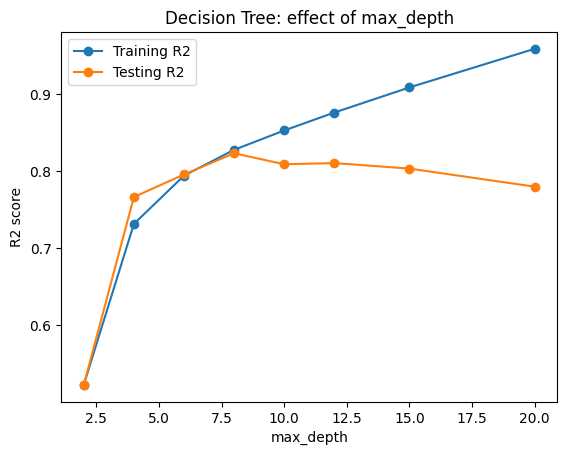

In [16]:
depths = [2, 4, 6, 8, 10, 12, 15, 20]
train_scores = []
test_scores = []

for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.plot(depths, train_scores, marker="o", label="Training R2")
plt.plot(depths, test_scores, marker="o", label="Testing R2")
plt.title("Decision Tree: effect of max_depth")
plt.xlabel("max_depth")
plt.ylabel("R2 score")
plt.legend()
plt.show()

*When the training score keeps rising but the testing score stops improving, the tree is starting to overfit.*

## 8. Visualize the results

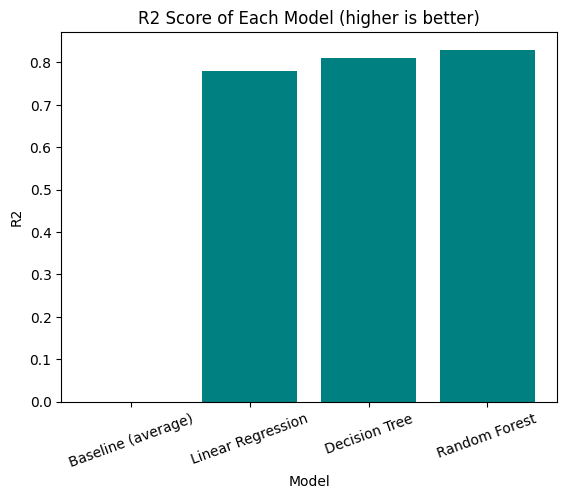

In [17]:
plt.bar(results_table["Model"], results_table["R2"], color="teal")
plt.title("R2 Score of Each Model (higher is better)")
plt.xlabel("Model")
plt.ylabel("R2")
plt.xticks(rotation=20)
plt.show()

*Shows which model explains sales best.*

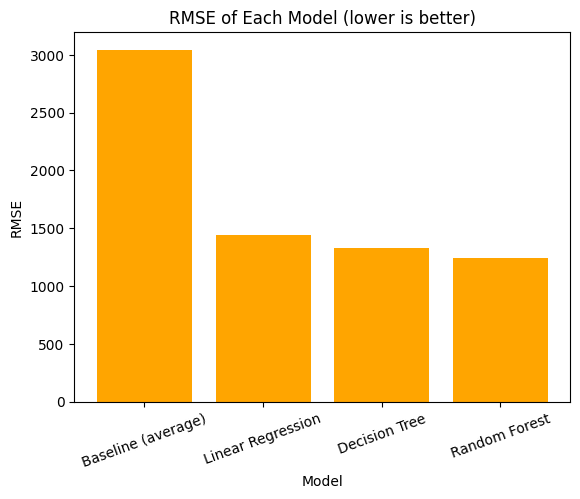

In [18]:
plt.bar(results_table["Model"], results_table["RMSE"], color="orange")
plt.title("RMSE of Each Model (lower is better)")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.show()

*Shows the average prediction error of each model.*

Best model: Random Forest


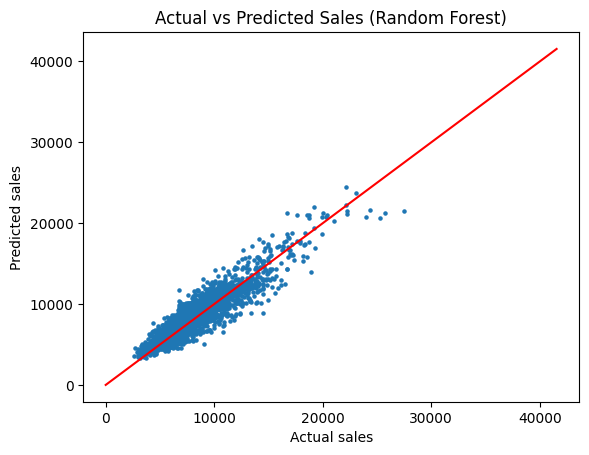

In [19]:
best = results_table.sort_values("R2", ascending=False).iloc[0]["Model"]
print("Best model:", best)

best_model = {"Linear Regression": lr, "Decision Tree": dt, "Random Forest": rf}.get(best, rf)
pred = best_model.predict(X_test)

plt.scatter(y_test[:3000], pred[:3000], s=5)
plt.plot([0, y_test.max()], [0, y_test.max()], color="red")
plt.title("Actual vs Predicted Sales (" + best + ")")
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.show()

*Points close to the red line mean good predictions.*

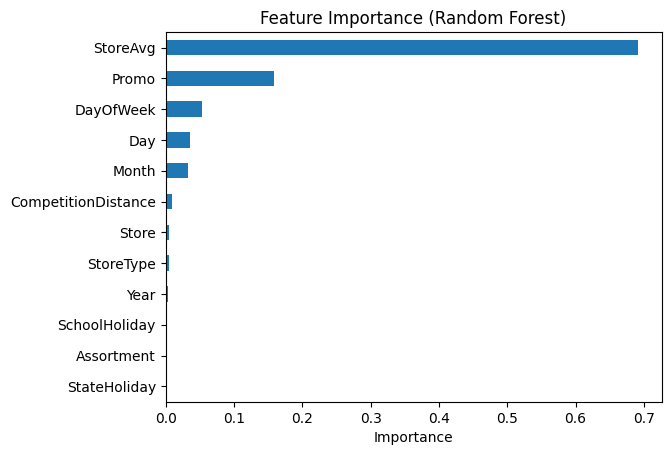

In [20]:
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

*Shows which columns the Random Forest used most to predict sales.*

## 9. Conclusion
The model with the highest R² and lowest error in the table above is our best model. Write the final numbers in your report.

### Done today
- [x] Problem definition, data cleaning and EDA
- [x] Features, train/test split
- [x] Baseline, Linear Regression, Decision Tree, Random Forest
- [x] Model comparison and visualizations

### Left for next time
- [ ] Save the final model and test predictions
- [ ] Deploy with Streamlit or Hugging Face
- [ ] Monitoring ideas
- [ ] Final report, presentation and demo